In [ ]:
import os, zipfile, hashlib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Upload EuroSAT_RGB.zip via the Files panel (left sidebar) first
ZIP = '/content/EuroSAT_RGB.zip'
zipfile.ZipFile(ZIP).extractall('/content')
ROOT = '/content/EuroSAT_RGB'
classes = sorted(d for d in os.listdir(ROOT) if os.path.isdir(f'{ROOT}/{d}'))
print(classes)

['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


In [ ]:
rows = []
for c in classes:
    for f in sorted(os.listdir(f'{ROOT}/{c}')):
        p = f'{ROOT}/{c}/{f}'
        im = Image.open(p)
        a = np.asarray(im.convert('RGB'), dtype=np.float32)
        gray = a.mean(2)
        m, s = a.reshape(-1, 3).mean(0), a.reshape(-1, 3).std(0)
        edge = (np.abs(np.diff(gray, axis=1)).mean() + np.abs(np.diff(gray, axis=0)).mean()) / 2
        rows.append(dict(cls=c, file=f, w=im.size[0], h=im.size[1], mode=im.mode,
                         mR=m[0], mG=m[1], mB=m[2], sR=s[0], sG=s[1], sB=s[2],
                         bright=gray.mean(), contrast=gray.std(), edge=edge,
                         md5=hashlib.md5(open(p, 'rb').read()).hexdigest()))
df = pd.DataFrame(rows)
print(df.shape)
print(df.groupby(['w', 'h', 'mode']).size())
print('exact duplicates:', df.md5.duplicated().sum())
df.cls.value_counts()

(27000, 15)
w   h   mode
64  64  RGB     27000
dtype: int64
exact duplicates: 0


,count
cls,
AnnualCrop,3000
Forest,3000
HerbaceousVegetation,3000
Residential,3000
SeaLake,3000
Highway,2500
PermanentCrop,2500
Industrial,2500
River,2500


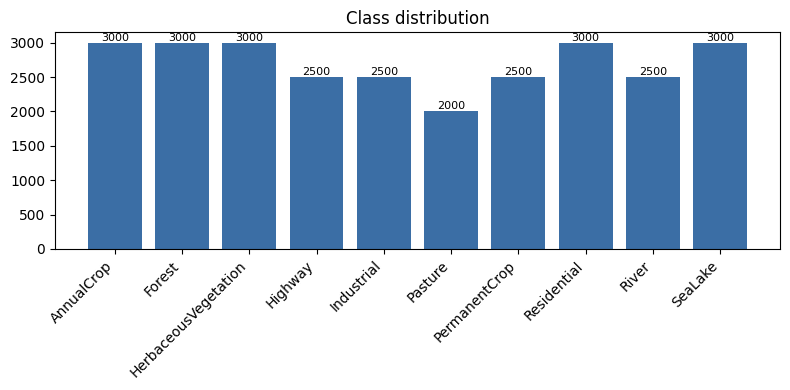

In [ ]:
vc = df.cls.value_counts().reindex(classes)
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(classes, vc.values, color='#3b6ea5')
ax.set_xticks(range(len(classes)))
ax.set_xticklabels(classes, rotation=45, ha='right')
for i, v in enumerate(vc.values):
    ax.text(i, v + 30, str(v), ha='center', fontsize=8)
ax.set_title('Class distribution'); plt.tight_layout(); plt.show()

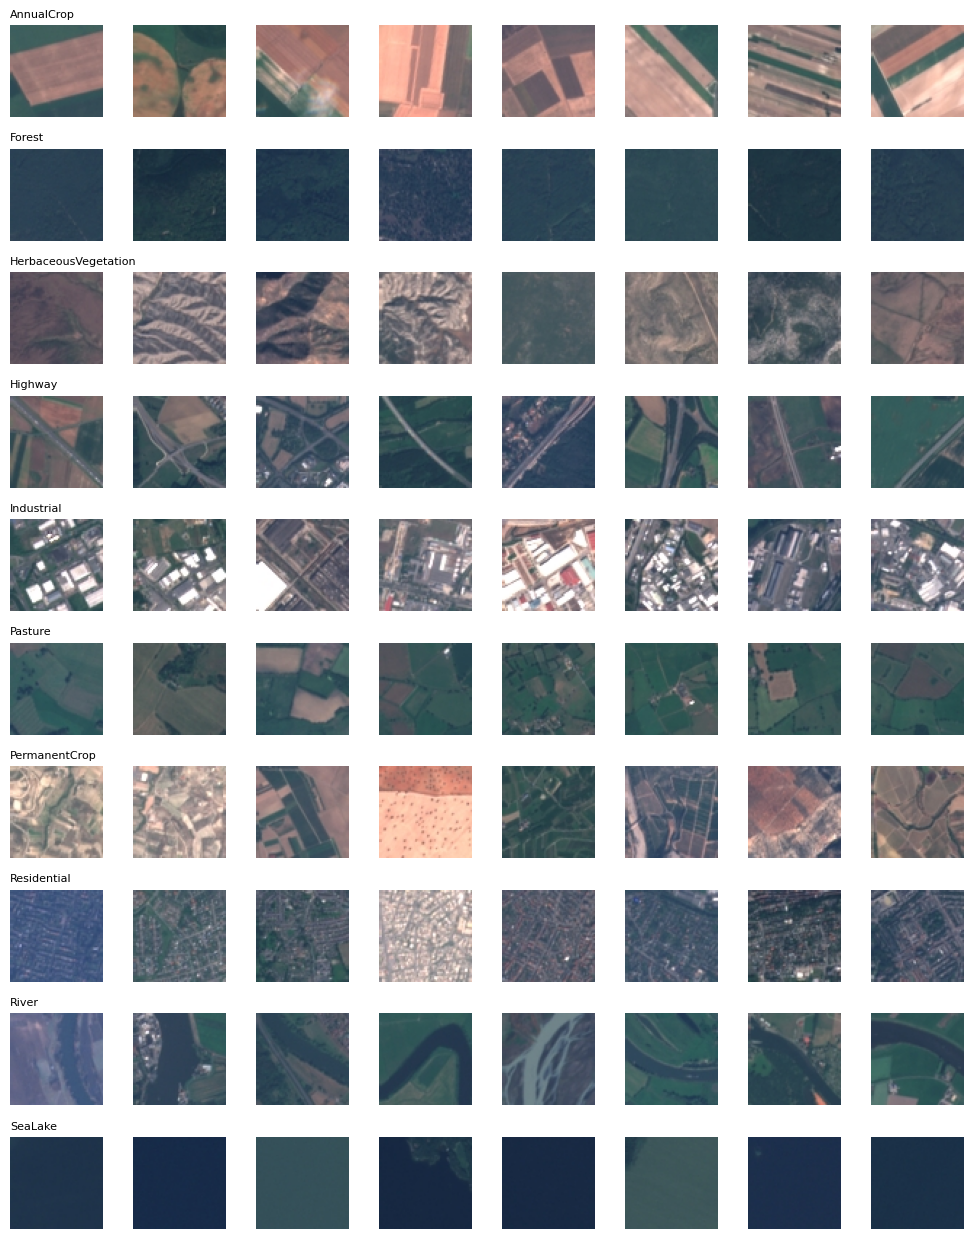

In [ ]:
rng = np.random.default_rng(1)
fig, axs = plt.subplots(10, 8, figsize=(10, 12.5))
for r, c in enumerate(classes):
    ids = rng.choice(np.where(df.cls == c)[0], 8, replace=False)
    for k, i in enumerate(ids):
        axs[r, k].imshow(Image.open(f'{ROOT}/{c}/{df.file[i]}')); axs[r, k].axis('off')
    axs[r, 0].set_title(c, fontsize=8, loc='left')
plt.tight_layout(); plt.show()

                              mR          mG          mB      bright  \
cls                                                                    
AnnualCrop            129.600006  120.000000  117.199997  122.300003   
Forest                 39.400002   64.500000   76.000000   59.900002   
HerbaceousVegetation   98.199997   98.699997  103.900002  100.300003   
Highway                88.000000   96.699997  103.400002   96.000000   
Industrial            123.400002  125.400002  134.300003  127.699997   
Pasture                61.900002   88.500000   94.199997   81.500000   
PermanentCrop         122.099998  116.000000  114.000000  117.400002   
Residential           100.099998  103.800003  113.000000  105.599998   
River                  67.000000   86.599998   96.900002   83.500000   
SeaLake                48.099998   72.800003   89.099998   70.000000   

                       contrast  edge  
cls                                    
AnnualCrop            25.000000   3.6  
Forest         

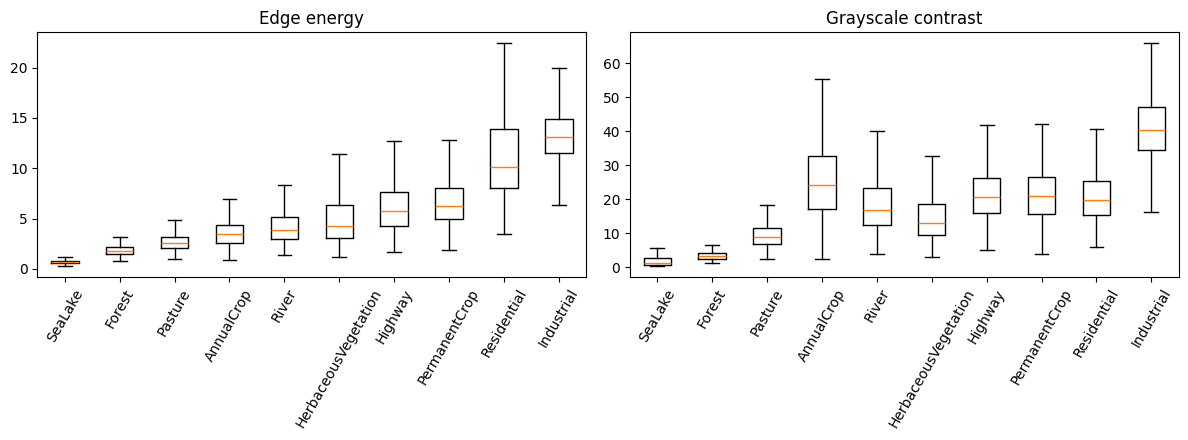

In [ ]:
print(df.groupby('cls')[['mR', 'mG', 'mB', 'bright', 'contrast', 'edge']].mean().round(1))

order = df.groupby('cls').edge.median().sort_values().index
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
axs[0].boxplot([df[df.cls == c].edge for c in order], tick_labels=order, showfliers=False)
axs[0].set_title('Edge energy'); axs[0].tick_params(axis='x', rotation=60)
axs[1].boxplot([df[df.cls == c].contrast for c in order], tick_labels=order, showfliers=False)
axs[1].set_title('Grayscale contrast'); axs[1].tick_params(axis='x', rotation=60)
plt.tight_layout(); plt.show()

In [ ]:
from sklearn.neighbors import NearestNeighbors

X16 = np.stack([np.asarray(Image.open(f'{ROOT}/{c}/{f}').convert('RGB').resize((16, 16), Image.BILINEAR))
                for c, f in zip(df.cls, df.file)])
G = X16.reshape(len(df), -1).astype(np.float32) / 255
d, idx = NearestNeighbors(n_neighbors=2).fit(G).kneighbors(G)
nd = d[:, 1]
close = nd < 0.15   # threshold chosen by eye; vary it and see how the count changes
print('images with a very close neighbour:', close.sum(), f'({close.mean():.1%})')
print('neighbour in same class:', (df.cls.values[idx[close, 1]] == df.cls.values[close]).mean())

images with a very close neighbour: 1596 (5.9%)
neighbour in same class: 0.9780701754385965


accuracy: 0.8467
                      precision    recall  f1-score   support

          AnnualCrop      0.884     0.903     0.894       600
              Forest      0.954     0.973     0.964       600
HerbaceousVegetation      0.821     0.793     0.807       600
             Highway      0.647     0.516     0.574       500
          Industrial      0.882     0.928     0.904       500
             Pasture      0.824     0.900     0.860       400
       PermanentCrop      0.747     0.744     0.745       500
         Residential      0.900     0.962     0.930       600
               River      0.716     0.732     0.724       500
             SeaLake      0.983     0.955     0.969       600

            accuracy                          0.847      5400
           macro avg      0.836     0.841     0.837      5400
        weighted avg      0.843     0.847     0.844      5400



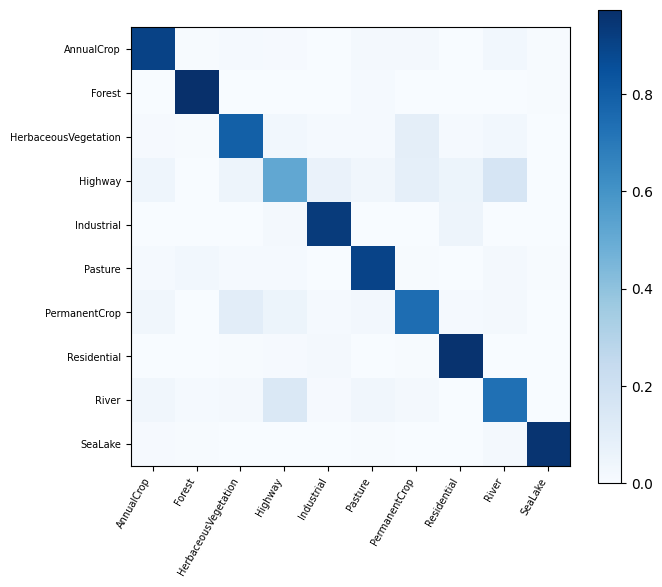

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

hist = np.zeros((len(df), 48), np.float32)
for i, (c, f) in enumerate(zip(df.cls, df.file)):
    a = np.asarray(Image.open(f'{ROOT}/{c}/{f}').convert('RGB'))
    for k in range(3):
        hist[i, k*16:(k+1)*16] = np.histogram(a[..., k], bins=16, range=(0, 256))[0] / 4096
feat = np.hstack([hist, df[['mR', 'mG', 'mB', 'sR', 'sG', 'sB', 'contrast', 'edge']].values / 255])
y = df.cls.values

tr, te = train_test_split(np.arange(len(df)), test_size=0.2, stratify=y, random_state=0)
rf = RandomForestClassifier(300, n_jobs=-1, random_state=0).fit(feat[tr], y[tr])
p = rf.predict(feat[te])
print('accuracy:', round(accuracy_score(y[te], p), 4))
print(classification_report(y[te], p, digits=3))

cm = confusion_matrix(y[te], p, labels=classes, normalize='true')
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap='Blues'); plt.colorbar(im)
ax.set_xticks(range(10)); ax.set_yticks(range(10))
ax.set_xticklabels(classes, rotation=60, ha='right', fontsize=7); ax.set_yticklabels(classes, fontsize=7)
plt.tight_layout(); plt.show()

In [ ]:
!pip -q install torchgeo

import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision.models import resnet18, ResNet18_Weights
from torchgeo.datasets import EuroSAT, EuroSATSpatial
from sklearn.metrics import f1_score

dev = 'cuda' if torch.cuda.is_available() else 'cpu'
mean = torch.tensor([0.485, 0.456, 0.406], device=dev).view(1, 3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225], device=dev).view(1, 3, 1, 1)

def make(DS, split):
    return DS('/content/eurosat_tg', split=split, bands=EuroSAT.rgb_bands, download=True)

def prep(batch):
    x = batch['image'].to(dev).float()
    x = (x / 3000).clamp(0, 1)                      # assumed reflectance scaling for RGB; check on a few images
    x = F.interpolate(x, size=224, mode='bilinear', align_corners=False)   # upsample, as in Corley et al.
    return (x - mean) / std, batch['label'].to(dev)

tg_classes = make(EuroSAT, 'test').classes
print(tg_classes)

['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


In [10]:
import numpy as np
import pandas as pd

def run(DS, epochs=1, bs=128, lr=3e-4):
    tr_ds, te_ds = make(DS, 'train'), make(DS, 'test')
    # Using num_workers=2 or 0 depending on environment
    tr = DataLoader(tr_ds, bs, shuffle=True, num_workers=2, pin_memory=True)
    te = DataLoader(te_ds, bs, num_workers=2, pin_memory=True)
    m = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
    m.fc = nn.Linear(512, 10); m.to(dev)
    opt = torch.optim.AdamW(m.parameters(), lr=lr)
    for ep in range(epochs):
        m.train()
        for b in tr:
            x, t = prep(b); opt.zero_grad()
            F.cross_entropy(m(x), t).backward(); opt.step()
    m.eval(); P, T = [], []
    with torch.no_grad():
        for b in te:
            x, t = prep(b); P += m(x).argmax(1).tolist(); T += t.tolist()
    P, T = np.array(P), np.array(T)
    return (P == T).mean(), f1_score(T, P, average=None), f1_score(T, P, average='macro')

# Run with 1 epoch for faster execution
acc_r, f1_r, mf_r = run(EuroSAT, epochs=1)          # random split (standard)
acc_s, f1_s, mf_s = run(EuroSATSpatial, epochs=1)   # longitude-based spatial split
print(f'random:  acc={acc_r:.4f}  macro-F1={mf_r:.4f}')
print(f'spatial: acc={acc_s:.4f}  macro-F1={mf_s:.4f}')

gap = pd.DataFrame({'random_F1': f1_r, 'spatial_F1': f1_s, 'drop': f1_r - f1_s}, index=tg_classes)
display(gap.sort_values('drop', ascending=False).round(3))

random:  acc=0.9517  macro-F1=0.9523
spatial: acc=0.8807  macro-F1=0.8356


,random_F1,spatial_F1,drop
PermanentCrop,0.933,0.353,0.580
Pasture,0.949,0.674,0.276
HerbaceousVegetation,0.937,0.774,0.163
Residential,0.986,0.884,0.103
AnnualCrop,0.956,0.887,0.069
River,0.964,0.907,0.057
Industrial,0.972,0.964,0.008
Highway,0.959,0.975,-0.015
SeaLake,0.934,0.951,-0.018
Forest,0.933,0.989,-0.056
